In [1]:
import joblib
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Định nghĩa đường dẫn 
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_RAW_PATH = BASE_DIR / 'data' / 'raw' / 'gas_turbine_data.csv'

OUTPUT_DIR = BASE_DIR / 'data' / 'processed'
MODELS_DIR = BASE_DIR / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Đọc dữ liệu và loại bỏ bản ghi trùng lặp
df_raw = pd.read_csv(DATA_RAW_PATH)
df = df_raw.drop_duplicates().copy()

print(f"[OK] Đã đọc {len(df_raw)} dòng, sau khi drop_duplicates còn {len(df)} dòng.")

# 3. Phân chia tập dữ liệu theo thời gian (2011-2013 vs 2014-2015)
train_df = df[df['year'].isin([2011, 2012, 2013])].copy()
test_df = df[df['year'].isin([2014, 2015])].copy()

# 4. Outlier Capping cho CO (Chỉ tính ngưỡng p99 từ train_df)
co_p99_threshold = train_df['CO'].quantile(0.99)
train_df['CO_clipped'] = train_df['CO'].clip(upper=co_p99_threshold)

test_df['CO_clipped'] = test_df['CO'].clip(upper=co_p99_threshold)

# 5. Scaler chỉ fit trên 9 đặc trưng đầu vào của Train
feature_cols = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
scaler = StandardScaler()

train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

# 6. Lưu file processed và lưu artifacts (Scaler + Capping Threshold)
train_df.to_csv(OUTPUT_DIR / 'train_clean.csv', index=False)
test_df.to_csv(OUTPUT_DIR / 'test_clean.csv', index=False)

# Lưu Scaler & Threshold ra thư mục models/ để tái lập suy luận sau này
joblib.dump(scaler, MODELS_DIR / 'scaler.joblib')
joblib.dump({'co_p99_threshold': co_p99_threshold}, MODELS_DIR / 'preprocessing_meta.joblib')

print(f"[THÀNH CÔNG] Đã lưu train_clean.csv ({len(train_df)} dòng) & test_clean.csv ({len(test_df)} dòng)")
print(f"[THÀNH CÔNG] Ngưỡng p99 CO tính từ Train: {co_p99_threshold:.4f} mg/m³")
print(f"[THÀNH CÔNG] Đã đóng gói scaler.joblib tại {MODELS_DIR}")

[OK] Đã đọc 36733 dòng, sau khi drop_duplicates còn 36726 dòng.
[THÀNH CÔNG] Đã lưu train_clean.csv (22191 dòng) & test_clean.csv (14535 dòng)
[THÀNH CÔNG] Ngưỡng p99 CO tính từ Train: 10.7166 mg/m³
[THÀNH CÔNG] Đã đóng gói scaler.joblib tại d:\BTL---Machine-Learning---co3117-\models


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

BASE_DIR = Path().resolve().parent if Path().resolve().name == 'notebooks' else Path().resolve()
data_path = BASE_DIR / 'data' / 'processed' / 'gas_turbine_clean.csv'

if not data_path.exists():
    data_path = BASE_DIR / 'data' / 'raw' / 'gas_turbine_data.csv'

df = pd.read_csv(data_path)

print("=== TỔNG QUAN TỆP DỮ LIỆU ===")
print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head()

=== TỔNG QUAN TỆP DỮ LIỆU ===
Kích thước dữ liệu: 36726 dòng, 13 cột


,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,CO_clipped
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,0.32663
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,0.44784
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,0.45144
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,0.23107
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,0.26747


In [9]:
print("=== BẢNG THỐNG KÊ MÔ TẢ TỔNG QUAN ===")
df.describe().T

=== BẢNG THỐNG KÊ MÔ TẢ TỔNG QUAN ===


,count,mean,std,min,25%,50%,75%,max
year,36726.0,2012.985542,1.419032,2011.000000,2012.000000,2013.00000,2014.00000,2015.00000
AT,36726.0,17.711451,7.447561,-6.234800,11.779250,17.79800,23.66400,37.10300
AP,36726.0,1013.071521,6.463155,985.850000,1008.800000,1012.60000,1017.00000,1036.60000
AH,36726.0,77.864274,14.461250,24.085000,68.182500,80.46550,89.37375,100.20000
AFDP,36726.0,3.925410,0.773939,2.087400,3.355525,3.93745,4.37680,7.61060
GTEP,36726.0,25.563537,4.196157,17.698000,23.127250,25.10450,29.05900,40.71600
TIT,36726.0,1081.427166,17.537244,1000.800000,1071.800000,1085.90000,1097.00000,1100.90000
TAT,36726.0,546.158062,6.842901,511.040000,544.720000,549.88000,550.04000,550.61000
TEY,36726.0,133.506079,15.619558,100.020000,124.450000,133.73000,144.08000,179.50000
CDP,36726.0,12.060470,1.088861,9.851800,11.434000,11.96500,12.85375,15.15900


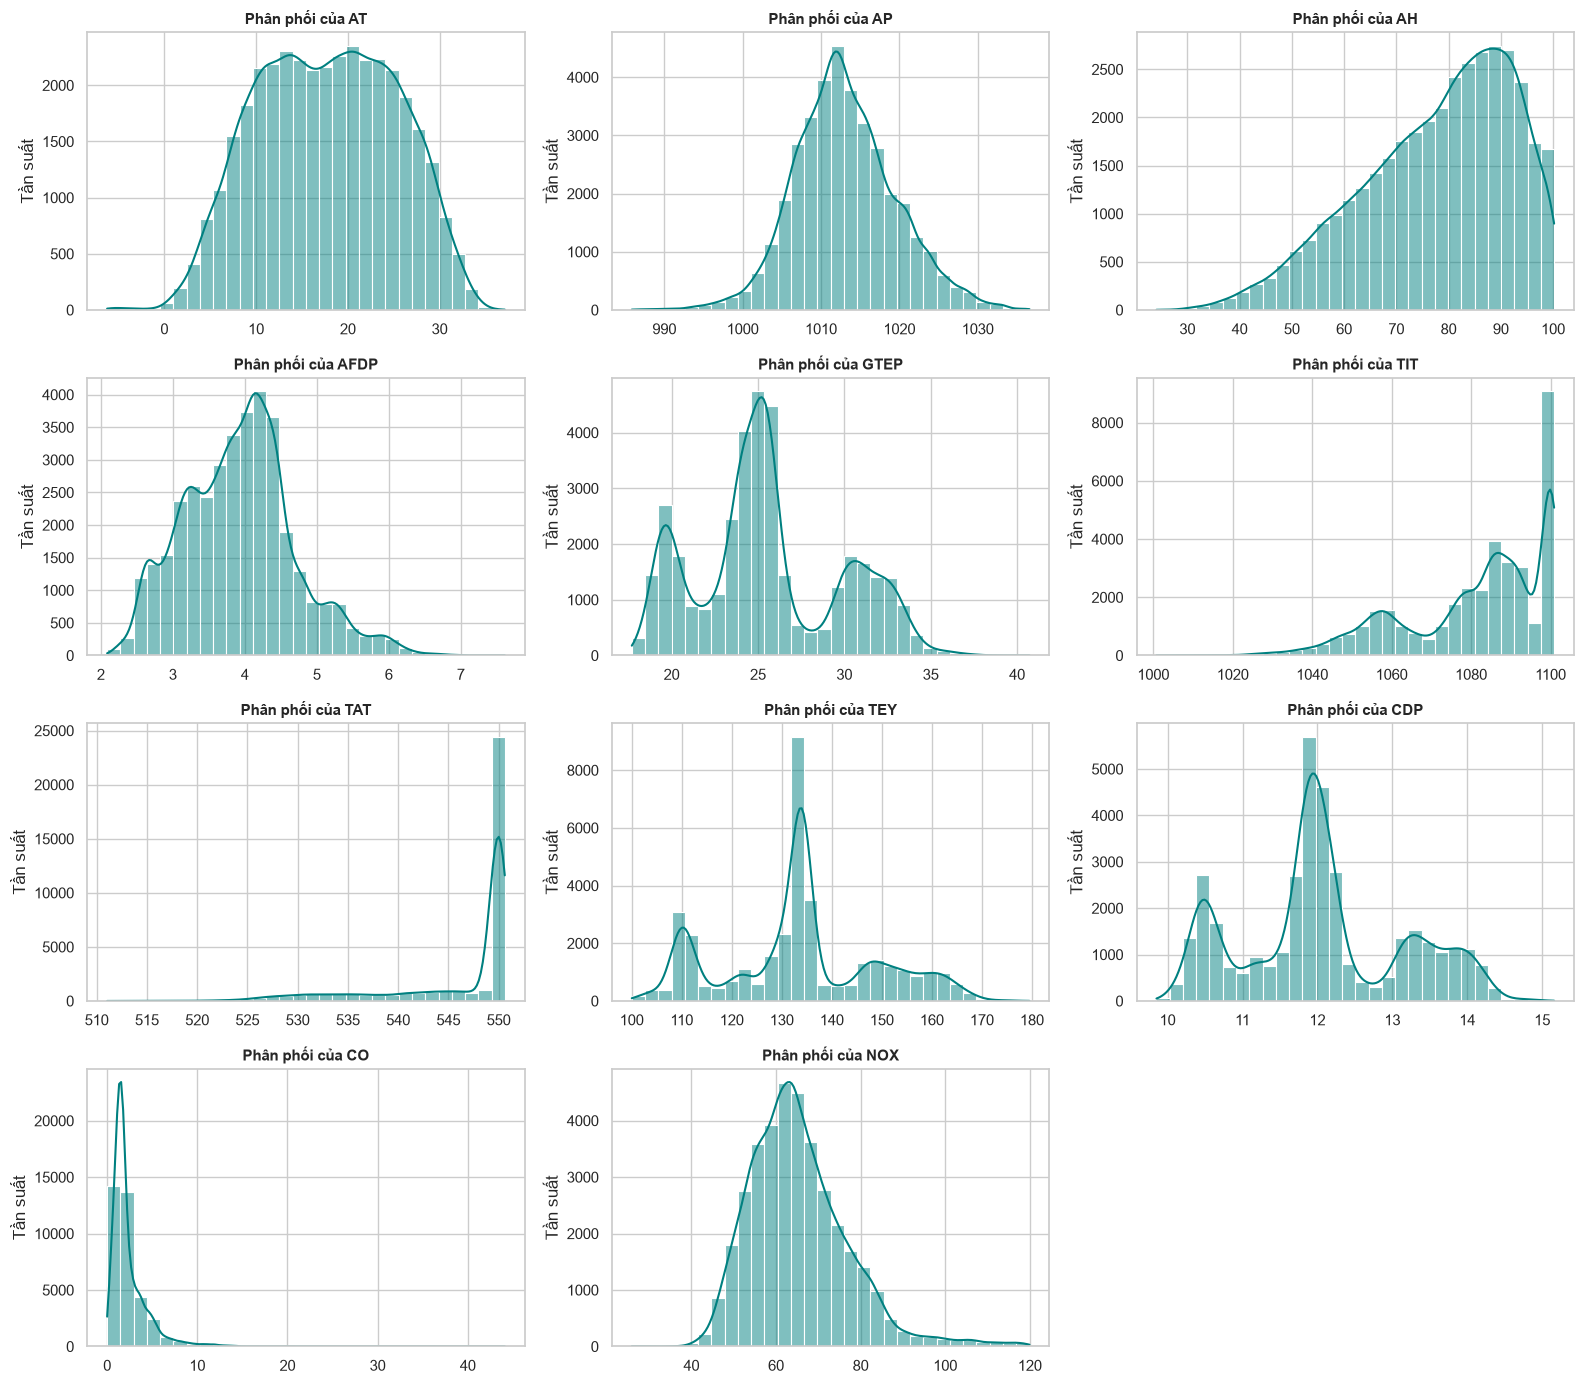

In [10]:
# 3. Trực quan hóa Phân phối các biến (Histogram & KDE)
features = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
targets = ['CO', 'NOX']
all_cols = features + targets

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Phân phối của {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Tần suất')

# Tắt ô trống thứ 12
axes[-1].axis('off')

plt.tight_layout()
plt.show()

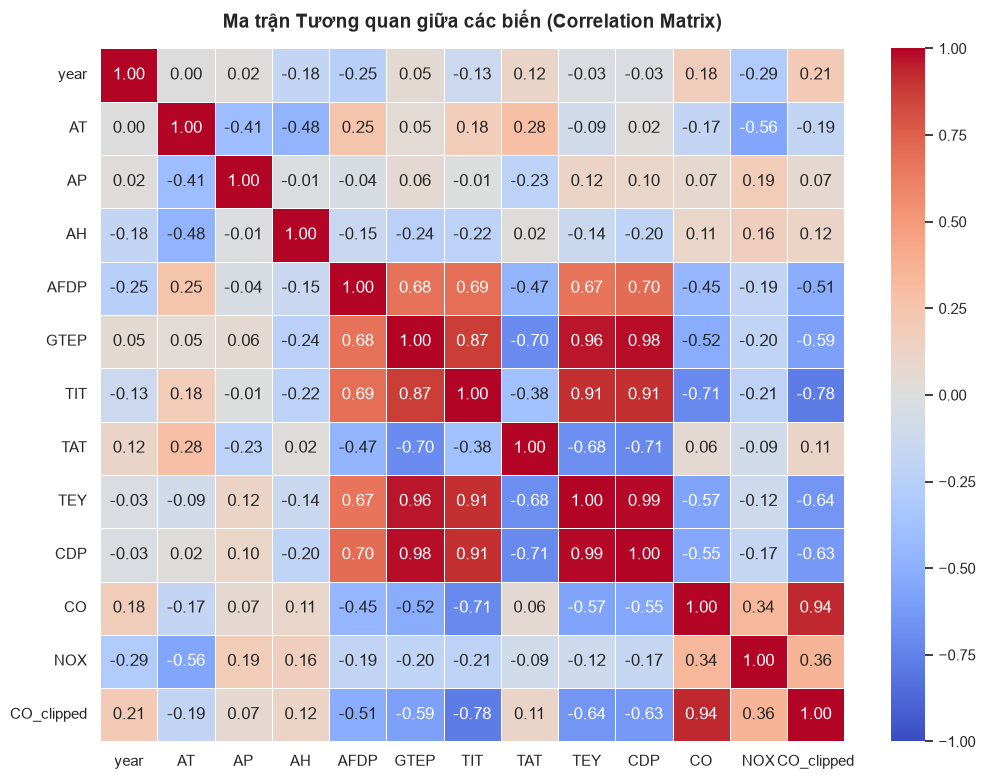

=== TƯƠNG QUAN VỚI CO (Sắp xếp giảm dần) ===
CO            1.000000
CO_clipped    0.937449
NOX           0.340580
year          0.178511
AH            0.106663
AP            0.066987
TAT           0.058376
AT           -0.174276
AFDP         -0.448410
GTEP         -0.518908
CDP          -0.551026
TEY          -0.569823
TIT          -0.706287
Name: CO, dtype: float64

=== TƯƠNG QUAN VỚI NOX (Sắp xếp giảm dần) ===
NOX           1.000000
CO_clipped    0.355936
CO            0.340580
AP            0.191700
AH            0.164931
TAT          -0.092711
TEY          -0.116150
CDP          -0.171247
AFDP         -0.188138
GTEP         -0.201617
TIT          -0.213869
year         -0.291802
AT           -0.558095
Name: NOX, dtype: float64


In [11]:
# 4. Biểu đồ Nhiệt Tương quan (Correlation Heatmap)
plt.figure(figsize=(12, 9))
corr_matrix = df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Ma trận Tương quan giữa các biến (Correlation Matrix)', fontsize=14, fontweight='bold', pad=15)
plt.show()

# In ra các biến có mức tương quan mạnh nhất với CO và NOX
print("=== TƯƠNG QUAN VỚI CO (Sắp xếp giảm dần) ===")
print(corr_matrix['CO'].sort_values(ascending=False))

print("\n=== TƯƠNG QUAN VỚI NOX (Sắp xếp giảm dần) ===")
print(corr_matrix['NOX'].sort_values(ascending=False))